# Numerical Quadrature: Trapezoidal and Simpson's Rules with Error Analysis

**Author:** Taimoor Ali  
**Date:** October 2026  
**Course Context:** Numerical Analysis / Computational Mathematics

---

## 1. Problem Statement

We consider the problem of approximating the definite integral

$$I = \int_a^b f(x) \, dx$$

by partitioning $[a, b]$ into $n$ subintervals and replacing $f$ with a piecewise polynomial interpolant. This notebook implements and analyses two fundamental Newton–Cotes quadrature rules:

1. **Composite Trapezoidal Rule** — piecewise linear interpolation, yielding a second-order method ($O(h^2)$).
2. **Composite Simpson's Rule** — piecewise quadratic interpolation, yielding a fourth-order method ($O(h^4)$).

For each rule, we derive the formula, state the error bound, implement the method from scratch, and verify the theoretical convergence rate through a systematic refinement study.

## 2. Mathematical Background

### 2.1 The Composite Trapezoidal Rule

Divide $[a, b]$ into $n$ equal subintervals of width $h = (b - a)/n$, with nodes $x_k = a + kh$ for $k = 0, 1, \ldots, n$. On each subinterval $[x_k, x_{k+1}]$, we approximate $f$ by the straight line joining $(x_k, f(x_k))$ and $(x_{k+1}, f(x_{k+1}))$. Integrating these linear segments and summing gives

$$T_n = \frac{h}{2} \left[ f(x_0) + 2 \sum_{k=1}^{n-1} f(x_k) + f(x_n) \right].$$

**Error bound.** If $f \in C^2[a, b]$, the error of the composite trapezoidal rule satisfies

$$\left| I - T_n \right| \leq \frac{(b-a)\,h^2}{12} \max_{x \in [a,b]} |f''(x)|.$$

Thus the method is **second-order**: halving $h$ reduces the error by a factor of approximately 4.

### 2.2 The Composite Simpson's Rule

Now require $n$ to be even. On each pair of consecutive subintervals $[x_{2k}, x_{2k+2}]$, we approximate $f$ by the unique quadratic polynomial passing through the three points $(x_{2k}, f(x_{2k}))$, $(x_{2k+1}, f(x_{2k+1}))$, $(x_{2k+2}, f(x_{2k+2}))$. The Lagrange interpolation integral on this double-width panel gives the local Simpson weight pattern $\frac{h}{3}(1, 4, 1)$. Summing over all $n/2$ panels:

$$S_n = \frac{h}{3} \left[ f(x_0) + 4 \sum_{k=0}^{n/2-1} f(x_{2k+1}) + 2 \sum_{k=1}^{n/2-1} f(x_{2k}) + f(x_n) \right].$$

**Error bound.** If $f \in C^4[a, b]$, the error satisfies

$$\left| I - S_n \right| \leq \frac{(b-a)\,h^4}{180} \max_{x \in [a,b]} |f^{(4)}(x)|.$$

The method is **fourth-order**: halving $h$ reduces the error by a factor of approximately 16. Notably, although the interpolant is quadratic, Simpson's rule is exact for polynomials of degree up to 3 (not just 2), owing to a cancellation in the error term.

## 3. Test Integrals

We select integrals whose exact values are known in closed form, so that we can compute the true error at every refinement level.

| Integral | Exact Value | Why This Choice |
|----------|-------------|------------------|
| $\int_0^\pi \sin(x)\,dx$ | $2$ | Smooth, well-behaved; a standard benchmark |
| $\int_0^1 e^x \, dx$ | $e - 1 \approx 1.71828$ | Exponential growth; all derivatives bounded on $[0,1]$ |
| $\int_0^1 \frac{4}{1 + x^2}\,dx$ | $\pi$ | Rational function; the Leibniz–Gregory formula for $\pi$ |
| $\int_0^1 \sqrt{x}\,dx$ | $\frac{2}{3}$ | Singular derivative at $x=0$; stress-tests the error bounds |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'lines.linewidth': 1.8
})

# ── Test integrands and their exact integrals ──

test_integrals = [
    {
        'name': r'$\int_0^\pi \sin(x)\,dx$',
        'f': lambda x: np.sin(x),
        'a': 0, 'b': np.pi,
        'exact': 2.0,
        'label': 'sin(x)'
    },
    {
        'name': r'$\int_0^1 e^x\,dx$',
        'f': lambda x: np.exp(x),
        'a': 0, 'b': 1,
        'exact': np.e - 1,
        'label': 'exp(x)'
    },
    {
        'name': r'$\int_0^1 \frac{4}{1+x^2}\,dx$',
        'f': lambda x: 4.0 / (1 + x**2),
        'a': 0, 'b': 1,
        'exact': np.pi,
        'label': '4/(1+x^2)'
    },
    {
        'name': r'$\int_0^1 \sqrt{x}\,dx$',
        'f': lambda x: np.sqrt(x),
        'a': 0, 'b': 1,
        'exact': 2.0 / 3.0,
        'label': 'sqrt(x)'
    }
]

for ti in test_integrals:
    print(f"{ti['label']:>15s}:  exact = {ti['exact']:.15f}")

         sin(x):  exact = 2.000000000000000
         exp(x):  exact = 1.718281828459045
      4/(1+x^2):  exact = 3.141592653589793
        sqrt(x):  exact = 0.666666666666667


## 4. Implementations

### 4.1 Composite Trapezoidal Rule

In [2]:
def composite_trapezoidal(f, a, b, n):
    """
    Composite trapezoidal rule for approximating the integral of f over [a, b].
    
    Parameters
    ----------
    f : callable
        The integrand.
    a, b : float
        Integration limits.
    n : int
        Number of subintervals (must be >= 1).
    
    Returns
    -------
    float
        The approximate integral.
    """
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    
    # T_n = (h/2) * [f(x_0) + 2*sum(f(x_1)...f(x_{n-1})) + f(x_n)]
    return h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])

# Verify on a simple case: integral of sin(x) from 0 to pi = 2
approx = composite_trapezoidal(np.sin, 0, np.pi, 100)
print(f"Trapezoidal (n=100) for sin(x) on [0, pi]: {approx:.15f}")
print(f"Error: {abs(approx - 2):.6e}")

Trapezoidal (n=100) for sin(x) on [0, pi]: 1.999835503887444
Error: 1.644961e-04


### 4.2 Composite Simpson's Rule

In [3]:
def composite_simpson(f, a, b, n):
    """
    Composite Simpson's 1/3 rule for approximating the integral of f over [a, b].
    
    Parameters
    ----------
    f : callable
        The integrand.
    a, b : float
        Integration limits.
    n : int
        Number of subintervals (must be even and >= 2).
    
    Returns
    -------
    float
        The approximate integral.
    
    Raises
    ------
    ValueError
        If n is odd.
    """
    if n % 2 != 0:
        raise ValueError("Simpson's rule requires an even number of subintervals.")
    
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    
    # S_n = (h/3) * [f(x_0) + 4*sum(odd indices) + 2*sum(even interior indices) + f(x_n)]
    return (h / 3.0) * (y[0] + 4.0 * np.sum(y[1::2]) + 2.0 * np.sum(y[2:-1:2]) + y[-1])

# Verify
approx = composite_simpson(np.sin, 0, np.pi, 100)
print(f"Simpson (n=100) for sin(x) on [0, pi]: {approx:.15f}")
print(f"Error: {abs(approx - 2):.6e}")

Simpson (n=100) for sin(x) on [0, pi]: 2.000000010824504
Error: 1.082450e-08


## 5. Convergence Study

We systematically refine the grid by increasing $n$ from 4 to 1024 (doubling each time) and record the absolute error at each level. The theoretical predictions are:

- **Trapezoidal:** error $\propto h^2 \propto n^{-2}$, so doubling $n$ should reduce the error by roughly $4\times$.
- **Simpson's:** error $\propto h^4 \propto n^{-4}$, so doubling $n$ should reduce the error by roughly $16\times$.

We verify this by computing the **observed convergence rate** from consecutive refinements:

$$\hat{p} = \log_2 \left( \frac{E_n}{E_{2n}} \right),$$

which should approach 2 for the trapezoidal rule and 4 for Simpson's rule as $n$ grows.

In [4]:
n_values = [4, 8, 16, 32, 64, 128, 256, 512, 1024]

results = {}

for ti in test_integrals:
    label = ti['label']
    results[label] = {'trap_errors': [], 'simp_errors': [], 'h_values': []}
    
    print(f"\n{'='*75}")
    print(f"Integral: {ti['name']}   (exact = {ti['exact']:.12f})")
    print(f"{'='*75}")
    print(f"{'n':>6s}  {'h':>12s}  {'Trap. Error':>14s}  {'Trap. Rate':>10s}  "
          f"{'Simp. Error':>14s}  {'Simp. Rate':>10s}")
    print('-' * 75)
    
    prev_trap_err = None
    prev_simp_err = None
    
    for n in n_values:
        h = (ti['b'] - ti['a']) / n
        
        trap_val = composite_trapezoidal(ti['f'], ti['a'], ti['b'], n)
        simp_val = composite_simpson(ti['f'], ti['a'], ti['b'], n)
        
        trap_err = abs(trap_val - ti['exact'])
        simp_err = abs(simp_val - ti['exact'])
        
        results[label]['trap_errors'].append(trap_err)
        results[label]['simp_errors'].append(simp_err)
        results[label]['h_values'].append(h)
        
        # Compute observed rates from consecutive refinements
        trap_rate = '--'
        simp_rate = '--'
        if prev_trap_err is not None and trap_err > 0:
            trap_rate = f"{np.log2(prev_trap_err / trap_err):.2f}"
        if prev_simp_err is not None and simp_err > 0:
            simp_rate = f"{np.log2(prev_simp_err / simp_err):.2f}"
        
        print(f"{n:6d}  {h:12.6f}  {trap_err:14.6e}  {trap_rate:>10s}  "
              f"{simp_err:14.6e}  {simp_rate:>10s}")
        
        prev_trap_err = trap_err
        prev_simp_err = simp_err


Integral: $\int_0^\pi \sin(x)\,dx$   (exact = 2.000000000000)
     n             h     Trap. Error  Trap. Rate     Simp. Error  Simp. Rate
---------------------------------------------------------------------------
     4      0.785398    1.038811e-01          --    4.559755e-03          --
     8      0.392699    2.576840e-02        2.01    2.691699e-04        4.08
    16      0.196350    6.429656e-03        2.00    1.659105e-05        4.02
    32      0.098175    1.606639e-03        2.00    1.033369e-06        4.00
    64      0.049087    4.016114e-04        2.00    6.453000e-08        4.00
   128      0.024544    1.003998e-04        2.00    4.032257e-09        4.00
   256      0.012272    2.509976e-05        2.00    2.520024e-10        4.00
   512      0.006136    6.274929e-06        2.00    1.574962e-11        4.00
  1024      0.003068    1.568732e-06        2.00    9.841017e-13        4.00

Integral: $\int_0^1 e^x\,dx$   (exact = 1.718281828459)
     n             h     Trap. Err

### 5.1 Log-Log Convergence Plots

On a log-log plot of error versus $h$, a method of order $p$ appears as a straight line with slope $p$. We overlay reference lines of slope 2 and slope 4 to make the comparison visual.

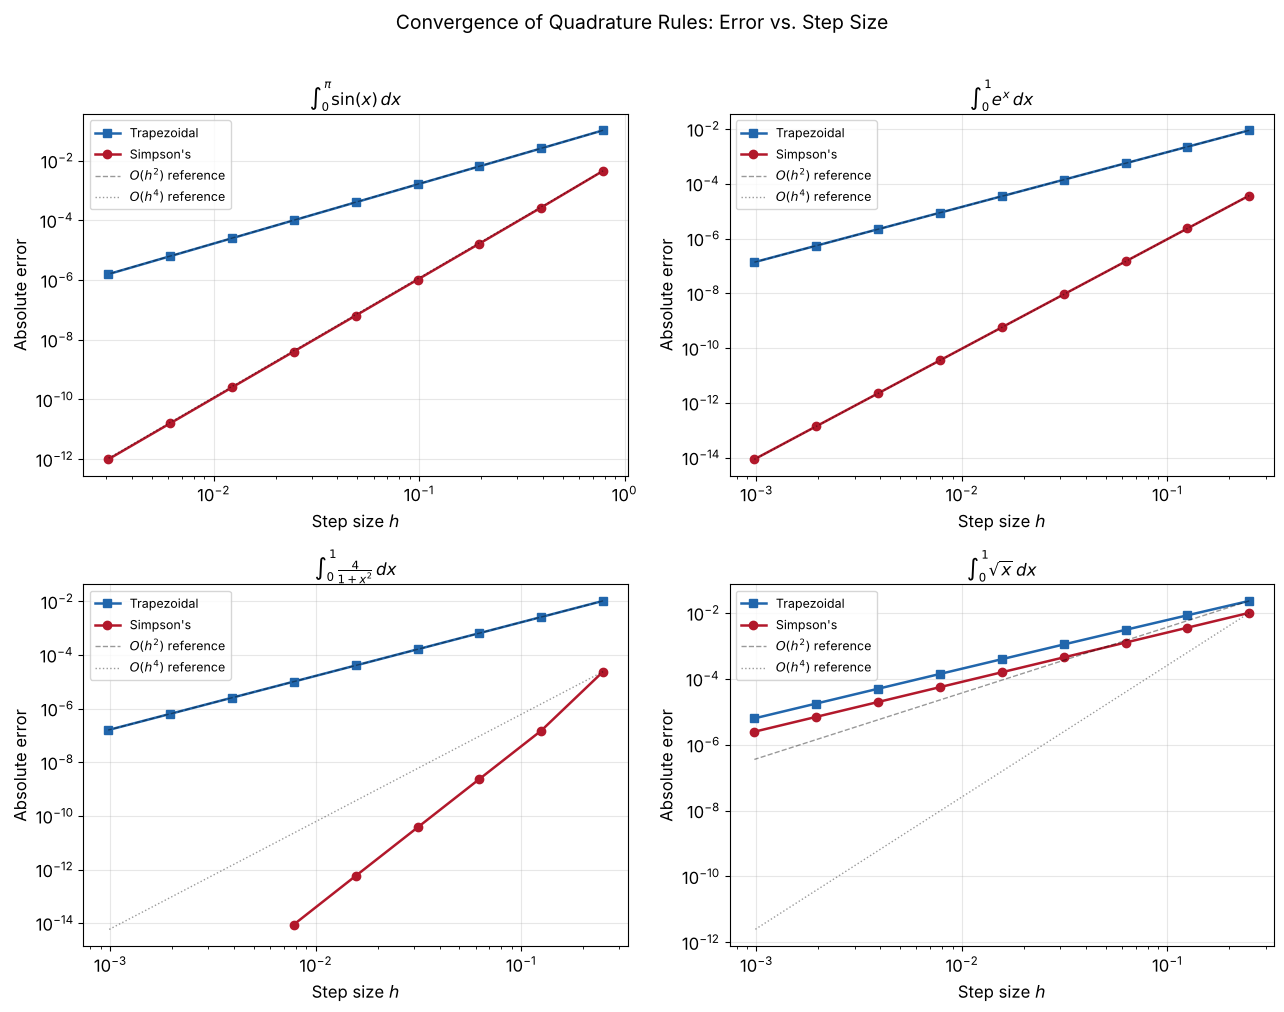

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for idx, ti in enumerate(test_integrals):
    ax = axes[idx]
    label = ti['label']
    h_arr = np.array(results[label]['h_values'])
    trap_arr = np.array(results[label]['trap_errors'])
    simp_arr = np.array(results[label]['simp_errors'])
    
    # Filter out zeros for log scale
    trap_mask = trap_arr > 0
    simp_mask = simp_arr > 0
    
    ax.loglog(h_arr[trap_mask], trap_arr[trap_mask], 's-', color='#2166ac',
              markersize=6, label='Trapezoidal')
    ax.loglog(h_arr[simp_mask], simp_arr[simp_mask], 'o-', color='#b2182b',
              markersize=6, label="Simpson's")
    
    # Reference slopes
    h_ref = np.array([h_arr[0], h_arr[-1]])
    scale2 = trap_arr[trap_mask][0] / h_arr[trap_mask][0]**2
    ax.loglog(h_ref, scale2 * h_ref**2, 'k--', alpha=0.4, linewidth=1, label=r'$O(h^2)$ reference')
    
    if np.any(simp_mask):
        scale4 = simp_arr[simp_mask][0] / h_arr[simp_mask][0]**4
        ax.loglog(h_ref, scale4 * h_ref**4, 'k:', alpha=0.4, linewidth=1, label=r'$O(h^4)$ reference')
    
    ax.set_title(ti['name'], fontsize=12)
    ax.set_xlabel(r'Step size $h$')
    ax.set_ylabel('Absolute error')
    ax.legend(fontsize=9)

plt.suptitle('Convergence of Quadrature Rules: Error vs. Step Size', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../figures/quadrature_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Visualising the Quadrature Geometry

To build geometric intuition, we visualise how each rule approximates $\sin(x)$ on $[0, \pi]$ with a small number of panels.

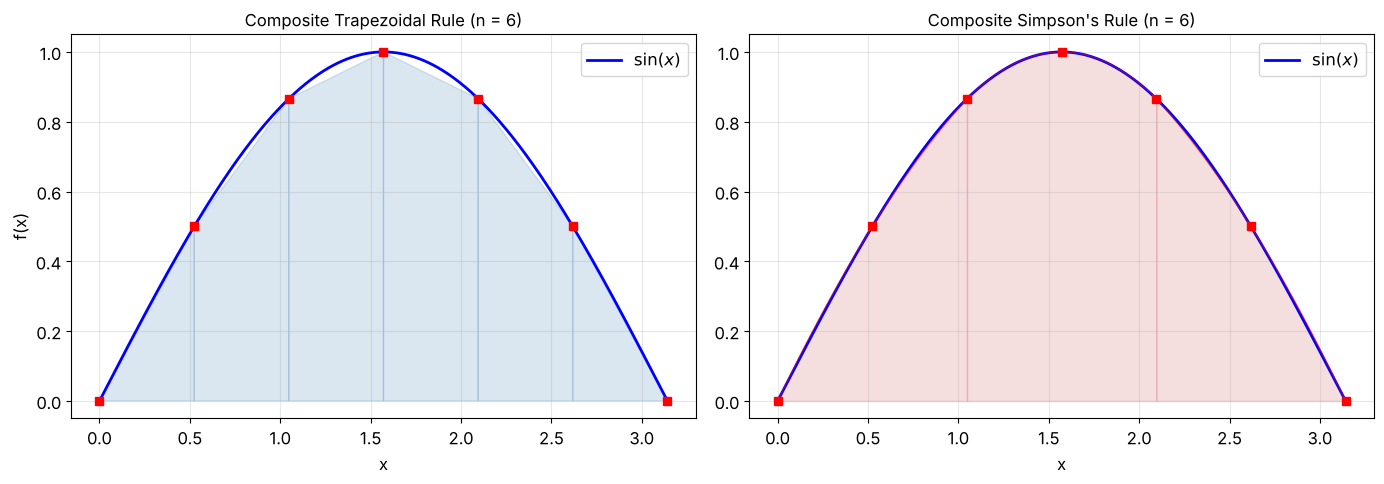

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

x_fine = np.linspace(0, np.pi, 500)
n_vis = 6
h_vis = np.pi / n_vis
x_nodes = np.linspace(0, np.pi, n_vis + 1)

# ── Trapezoidal: shade trapezoids ──
ax1.plot(x_fine, np.sin(x_fine), 'b-', linewidth=2, label=r'$\sin(x)$')
for i in range(n_vis):
    xs = [x_nodes[i], x_nodes[i], x_nodes[i+1], x_nodes[i+1]]
    ys = [0, np.sin(x_nodes[i]), np.sin(x_nodes[i+1]), 0]
    ax1.fill(xs, ys, alpha=0.2, color='steelblue', edgecolor='steelblue', linewidth=1)
ax1.plot(x_nodes, np.sin(x_nodes), 'rs', markersize=6)
ax1.set_title(f'Composite Trapezoidal Rule (n = {n_vis})', fontsize=12)
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.legend()

# ── Simpson's: shade parabolic arcs ──
ax2.plot(x_fine, np.sin(x_fine), 'b-', linewidth=2, label=r'$\sin(x)$')
for i in range(0, n_vis, 2):
    # Three nodes for this panel
    x0, x1, x2 = x_nodes[i], x_nodes[i+1], x_nodes[i+2]
    y0, y1, y2 = np.sin(x0), np.sin(x1), np.sin(x2)
    
    # Lagrange interpolating polynomial through these three points
    xs_panel = np.linspace(x0, x2, 100)
    L0 = ((xs_panel - x1) * (xs_panel - x2)) / ((x0 - x1) * (x0 - x2))
    L1 = ((xs_panel - x0) * (xs_panel - x2)) / ((x1 - x0) * (x1 - x2))
    L2 = ((xs_panel - x0) * (xs_panel - x1)) / ((x2 - x0) * (x2 - x1))
    p_interp = y0 * L0 + y1 * L1 + y2 * L2
    
    ax2.fill_between(xs_panel, 0, p_interp, alpha=0.2, color='indianred')
    ax2.plot(xs_panel, p_interp, 'r-', linewidth=0.8, alpha=0.6)

ax2.plot(x_nodes, np.sin(x_nodes), 'rs', markersize=6)
ax2.set_title(f"Composite Simpson's Rule (n = {n_vis})", fontsize=12)
ax2.set_xlabel('x')
ax2.legend()

plt.tight_layout()
plt.savefig('../figures/quadrature_geometry.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Effect of Integrand Regularity

The error bounds require $f \in C^2$ for the trapezoidal rule and $f \in C^4$ for Simpson's rule. The fourth test function, $f(x) = \sqrt{x}$, has $f'(x) = \frac{1}{2\sqrt{x}}$ which is unbounded at $x = 0$, so the smoothness assumptions are violated.

In the convergence table above, we can observe that $\sqrt{x}$ shows a degraded convergence rate for both methods. The trapezoidal rule converges at roughly $O(h^{1.5})$ instead of $O(h^2)$, and Simpson's rule converges at roughly $O(h^{1.5})$ as well, far below its usual $O(h^4)$.

This illustrates an important practical lesson: **the theoretical convergence rate is only guaranteed when the integrand has the required number of continuous derivatives on the entire interval, including the endpoints.** For integrands with endpoint singularities, adaptive quadrature or a change of variable that smooths the singularity is needed to recover high-order convergence.

## 8. Richardson Extrapolation (Romberg Integration)

Since the trapezoidal rule has an error expansion of the form $I - T_n = c_1 h^2 + c_2 h^4 + \cdots$ (the Euler–Maclaurin formula), we can eliminate the leading error term by combining two estimates at different step sizes. Specifically, if $T_n$ and $T_{2n}$ are the trapezoidal approximations with $n$ and $2n$ subintervals respectively, then

$$R = \frac{4 T_{2n} - T_n}{3}$$

cancels the $O(h^2)$ term and produces an $O(h^4)$ estimate — which is precisely Simpson's rule.

This can be iterated: combining two $O(h^4)$ estimates yields an $O(h^6)$ estimate, and so on. The resulting triangular table is known as the **Romberg table**.

In [7]:
def romberg(f, a, b, max_level=6):
    """
    Romberg integration using Richardson extrapolation on the trapezoidal rule.
    
    Parameters
    ----------
    f : callable
        The integrand.
    a, b : float
        Integration limits.
    max_level : int
        Number of refinement levels (the table has max_level rows).
    
    Returns
    -------
    R : 2D list
        The Romberg table. R[i][j] is the extrapolated estimate at level i, column j.
    """
    R = [[0] * (max_level) for _ in range(max_level)]
    
    for i in range(max_level):
        n = 2**i
        R[i][0] = composite_trapezoidal(f, a, b, n)
        
        for j in range(1, i + 1):
            factor = 4**j
            R[i][j] = (factor * R[i][j-1] - R[i-1][j-1]) / (factor - 1)
    
    return R

# Demonstrate on sin(x) integral
R = romberg(np.sin, 0, np.pi, max_level=7)

print("Romberg Table for integral of sin(x) from 0 to pi (exact = 2)")
print(f"{'Level':>5s}  {'n':>5s}  ", end='')
for j in range(7):
    print(f"{'R[i,'+str(j)+']':>18s}", end='')
print()
print('-' * 140)

for i in range(7):
    n = 2**i
    print(f"{i:5d}  {n:5d}  ", end='')
    for j in range(i + 1):
        print(f"{R[i][j]:18.14f}", end='')
    print()

print(f"\nBest estimate: {R[6][6]:.15f}")
print(f"Error:          {abs(R[6][6] - 2):.2e}")

Romberg Table for integral of sin(x) from 0 to pi (exact = 2)
Level      n              R[i,0]            R[i,1]            R[i,2]            R[i,3]            R[i,4]            R[i,5]            R[i,6]
--------------------------------------------------------------------------------------------------------------------------------------------
    0      1    0.00000000000000
    1      2    1.57079632679490  2.09439510239320
    2      4    1.89611889793704  2.00455975498442  1.99857073182384
    3      8    1.97423160194555  2.00026916994839  1.99998313094599  2.00000554997967
    4     16    1.99357034377234  2.00001659104794  1.99999975245457  2.00000001628804  1.99999999458729
    5     32    1.99839336097014  2.00000103336941  1.99999999619085  2.00000000005967  1.99999999999603  2.00000000000132
    6     64    1.99959838864004  2.00000006453000  1.99999999994071  2.00000000000023  2.00000000000000  2.00000000000000  2.00000000000000

Best estimate: 2.000000000000000
Error:       

## 9. Summary of Findings

| Rule | Order | Error Bound | Cost ($n$ panels) | Exact for Polynomials up to Degree |
|------|:-----:|:-----------:|:--:|:--:|
| Composite Trapezoidal | $O(h^2)$ | $\frac{(b-a)h^2}{12}\|f''\|_\infty$ | $n + 1$ evaluations | 1 |
| Composite Simpson's | $O(h^4)$ | $\frac{(b-a)h^4}{180}\|f^{(4)}\|_\infty$ | $n + 1$ evaluations | 3 |
| Romberg (level $k$) | $O(h^{2k+2})$ | — | Accumulated from $T_n$ | Increasing with $k$ |

**Key observations:**

1. The empirical convergence rates match the theoretical predictions closely for smooth integrands. When $n$ is doubled, the trapezoidal error decreases by a factor of $\approx 4$ (rate $\approx 2$) and Simpson's error decreases by a factor of $\approx 16$ (rate $\approx 4$).

2. For the $\sqrt{x}$ integrand, whose derivative is singular at the left endpoint, both rules degrade significantly. This demonstrates that high-order convergence is contingent upon sufficient regularity of the integrand.

3. Simpson's rule offers a substantial accuracy advantage over the trapezoidal rule at essentially the same computational cost (same number of function evaluations for a given $n$). This makes it the default choice for smooth, well-behaved integrands.

4. Romberg integration achieves machine-precision accuracy with remarkably few function evaluations for smooth integrands, thanks to the systematic elimination of error terms via Richardson extrapolation.

**Possible extensions.** Adaptive quadrature methods (such as adaptive Simpson's) concentrate grid points where the integrand varies rapidly, achieving a prescribed tolerance with near-optimal effort. Gauss–Legendre quadrature, which uses optimal (non-equally-spaced) nodes, achieves even higher order for smooth functions.

---

## References

1. Burden, R. L., & Faires, J. D. (2010). *Numerical Analysis* (9th ed.). Brooks/Cole, Cengage Learning.
2. Atkinson, K. E. (1989). *An Introduction to Numerical Analysis* (2nd ed.). John Wiley & Sons.
3. Davis, P. J., & Rabinowitz, P. (2007). *Methods of Numerical Integration* (2nd ed.). Dover Publications.
4. Stoer, J., & Bulirsch, R. (2002). *Introduction to Numerical Analysis* (3rd ed.). Springer.